<a href="https://colab.research.google.com/github/madhurapote431/beginning-bioinformatics/blob/main/notebooks/Module11_Classifying_Cells_from_Gene_Expression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 11: Classifying Cells from Gene Expression
**Name:** Madhura Milind Pote  |  **Student ID:** 1002318685

Part A follows the Scanpy tutorial *Preprocessing and clustering* (through *Differentially-expressed Genes as Markers*). Part B appends the classification cells and exit questions.

## Part A: Scanpy tutorial
### Setup

In [ ]:
# %pip install -q "scanpy[leiden]" igraph leidenalg pooch scikit-misc scrublet

In [ ]:
%pip install -q "pandas==2.2.3" "scanpy[leiden]" "pynndescent==0.6.0"

In [ ]:
import pooch
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.set_figure_params(dpi=50, facecolor="white")
print("scanpy", sc.__version__)

scanpy 1.12


/tmp/ipykernel_10426/2598723481.py:8: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=50, facecolor="white")
/tmp/ipykernel_10426/2598723481.py:9: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__)


### Loading and combining the data

In [ ]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorial"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": "s1d3_filtered_feature_bc_matrix.h5",
}
adatas = {}
for sample_id, filename in samples.items():
    path = EXAMPLE_DATA.fetch(filename)
    sample_adata = sc.read_10x_h5(path)
    sample_adata.var_names_make_unique()
    adatas[sample_id] = sample_adata

adata = ad.concat(adatas, label="sample")
adata.obs_names_make_unique()
print(adata.obs["sample"].value_counts())
adata

/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'

### Quality control

In [ ]:
# mitochondrial, ribosomal and hemoglobin genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True
)

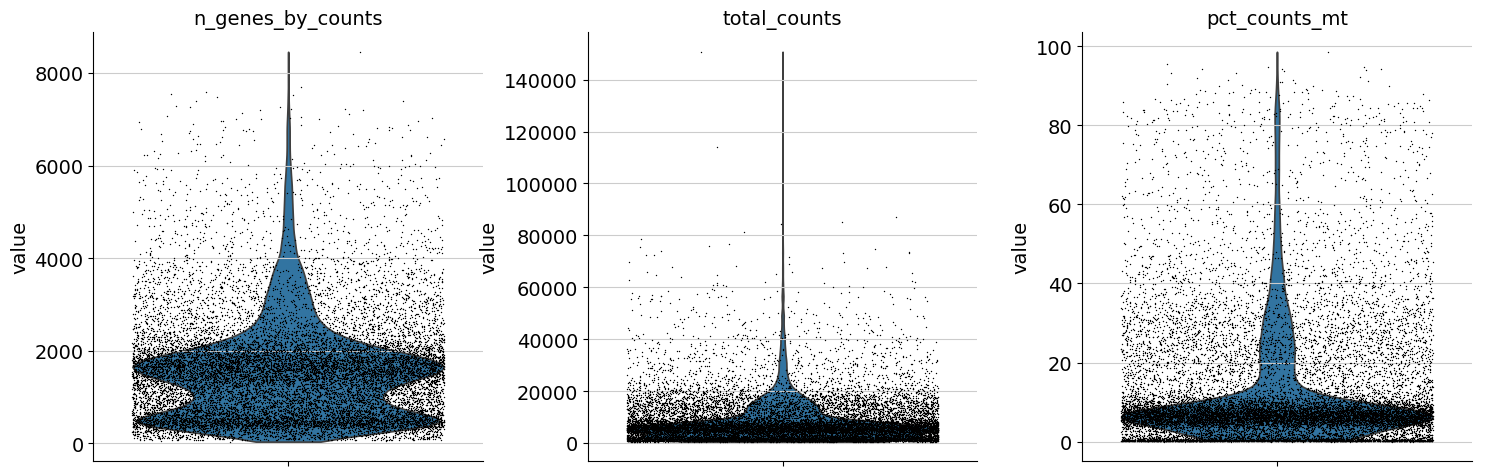

In [ ]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

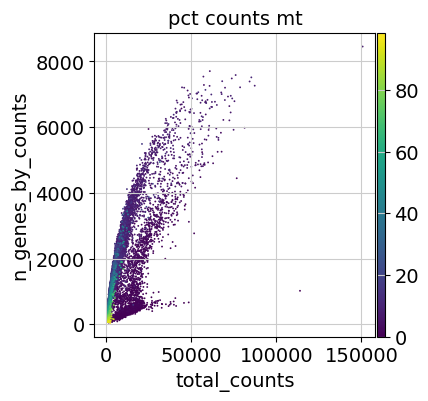

In [ ]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [ ]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)

### Doublet detection

In [ ]:
sc.pp.scrublet(adata, batch_key="sample")

### Normalization

In [ ]:
# Saving count data
adata.layers["counts"] = adata.X.copy()

In [ ]:
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

### Feature selection

In [ ]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")

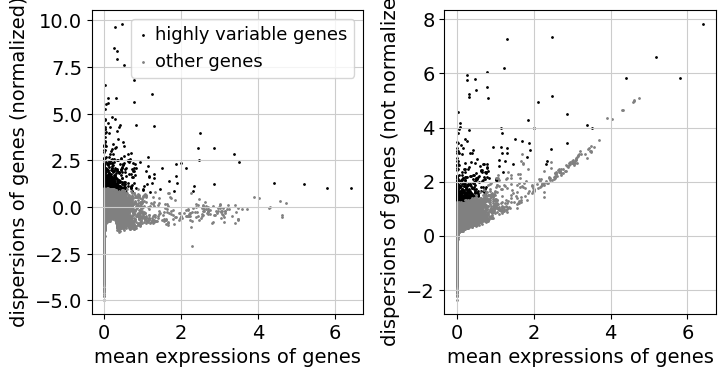

In [ ]:
sc.pl.highly_variable_genes(adata)

### Dimensionality reduction

In [ ]:
sc.tl.pca(adata)

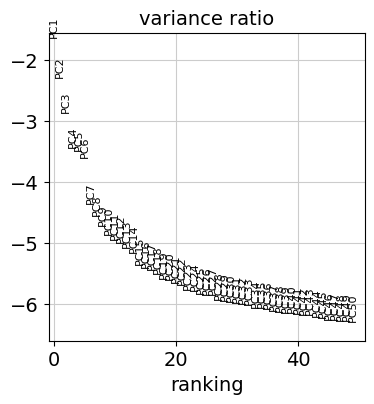

In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

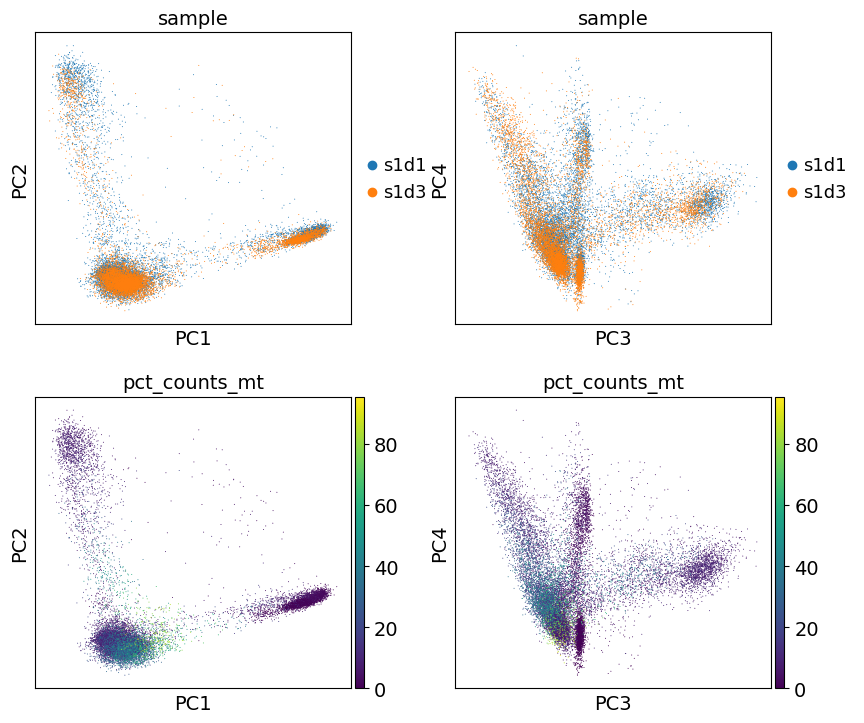

In [ ]:
sc.pl.pca(
    adata,
    color=["sample", "sample", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

### Nearest neighbor graph constuction and visualization

In [ ]:
sc.pp.neighbors(adata)

In [ ]:
sc.tl.umap(adata)

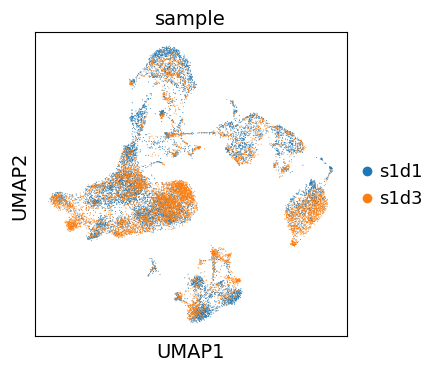

In [ ]:
sc.pl.umap(adata, color="sample", size=2)

### Clustering

In [ ]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster, especially for larger datasets
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(
        adata,
        key_added=f"leiden_res_{res:4.2f}",
        resolution=res,
        flavor="igraph",
        n_iterations=2,
    )

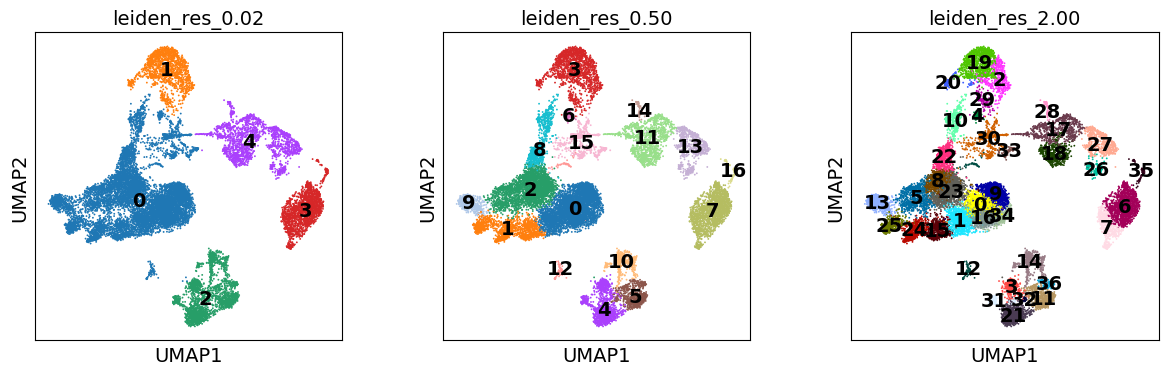

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data",
)

### Re-assess quality control and cell filtering

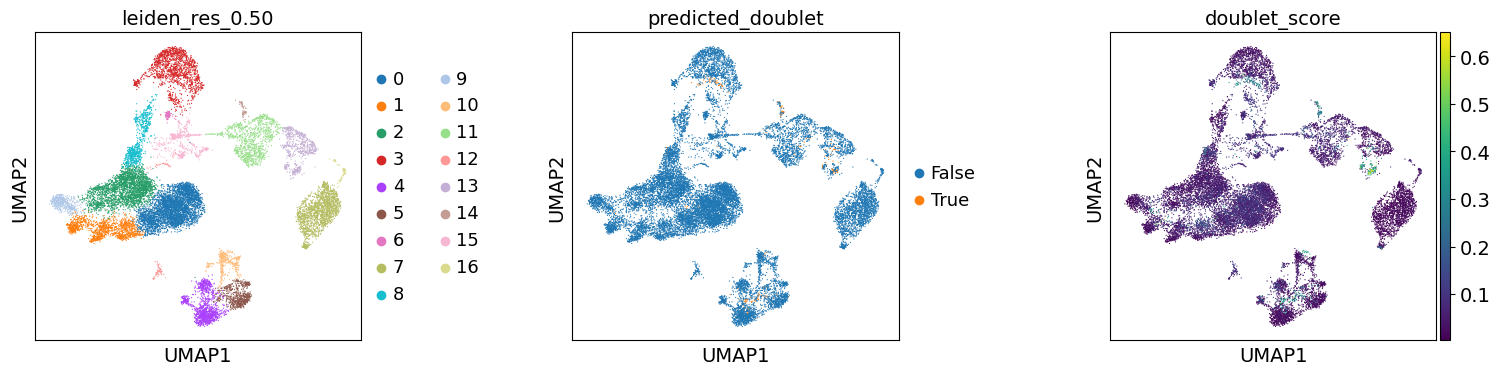

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res_0.50", "predicted_doublet", "doublet_score"],
    wspace=0.5,
    size=3,
)

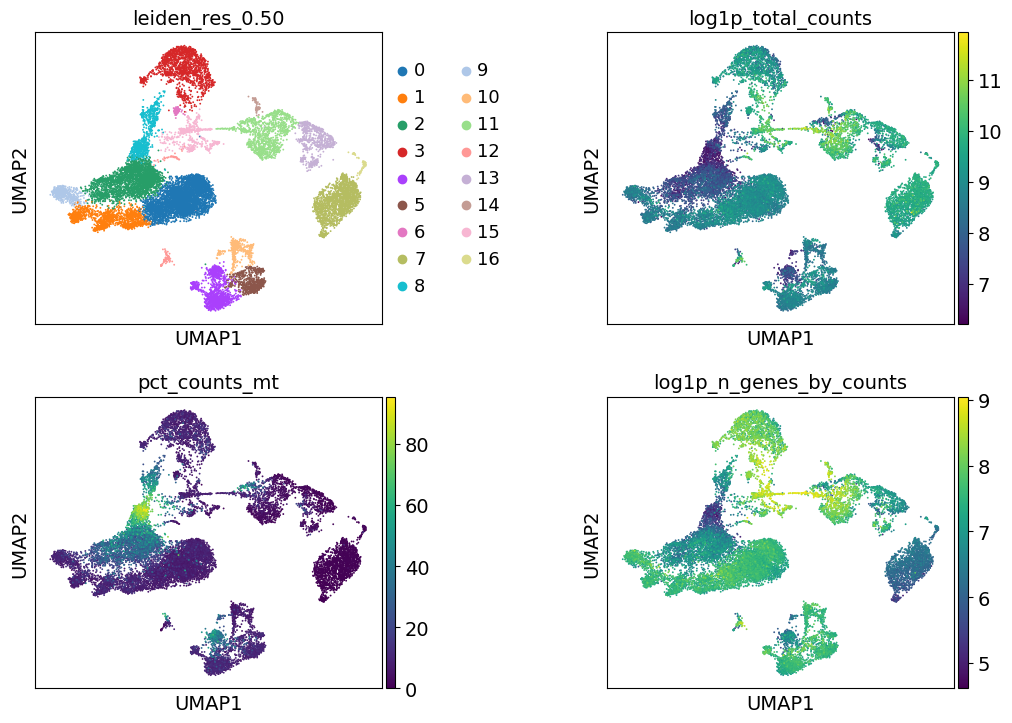

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res_0.50", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

### Manual cell-type annotation

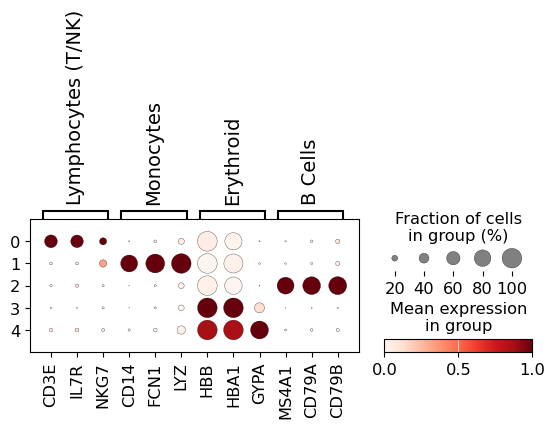

In [ ]:
for res in [0.02, 0.5, 2.0]:
    adata.obs[f"leiden_res_{res:4.2f}"] = adata.obs[f"leiden_res_{res:4.2f}"].astype("category")

marker_genes = {
    "Lymphocytes (T/NK)": ["CD3E", "IL7R", "NKG7"],
    "Monocytes": ["CD14", "FCN1", "LYZ"],
    "Erythroid": ["HBB", "HBA1", "GYPA"],
    "B Cells": ["MS4A1", "CD79A", "CD79B"],
}
marker_genes = {k: [g for g in v if g in adata.var_names] for k, v in marker_genes.items()}
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.02", standard_scale="var")

The tutorial assigns the level-1 labels by reading this dot plot. To avoid hard-coding cluster numbers that might differ in your run, the next cell assigns each resolution-0.02 cluster to the marker set it expresses most (relative to the other clusters). **Check the printed mapping against the dot plot above.** If a cluster looks wrong, edit the `manual` dictionary and set `USE_MANUAL = True`.

In [ ]:
X_log = adata.X
clusters = adata.obs["leiden_res_0.02"].astype(str)
score = {}
for ct, genes in marker_genes.items():
    idx = [adata.var_names.get_loc(g) for g in genes]
    sub = X_log[:, idx]
    sub = sub.toarray() if hasattr(sub, "toarray") else np.asarray(sub)
    score[ct] = pd.Series(sub.mean(axis=1), index=adata.obs_names).groupby(clusters.values).mean()
score = pd.DataFrame(score)
z = (score - score.mean()) / score.std(ddof=0).replace(0, 1)
auto_map = z.idxmax(axis=1).to_dict()
print(score.round(2))
print("\nAutomatic mapping:", auto_map)

USE_MANUAL = False
manual = {"0": "Lymphocytes (T/NK)", "1": "Monocytes", "2": "Erythroid", "3": "B Cells"}  # edit if needed
cluster_map = manual if USE_MANUAL else auto_map

label_map = {"Lymphocytes (T/NK)": "Lymphocytes"}
adata.obs["cell_type_lvl1"] = (
    adata.obs["leiden_res_0.02"].astype(str).map(cluster_map).replace(label_map)
)
print(adata.obs["cell_type_lvl1"].value_counts())

   Lymphocytes (T/NK)  Monocytes  Erythroid  B Cells
0                0.75       0.13       1.41     0.08
1                0.11       2.48       1.33     0.05
2                0.07       0.08       1.33     1.66
3                0.01       0.03       4.85     0.01
4                0.06       0.11       4.78     0.04

Automatic mapping: {'0': 'Lymphocytes (T/NK)', '1': 'Monocytes', '2': 'B Cells', '3': 'Erythroid', '4': 'Erythroid'}
cell_type_lvl1
Lymphocytes    9763
Erythroid      3502
B Cells        2269
Monocytes      1507
Name: count, dtype: int64


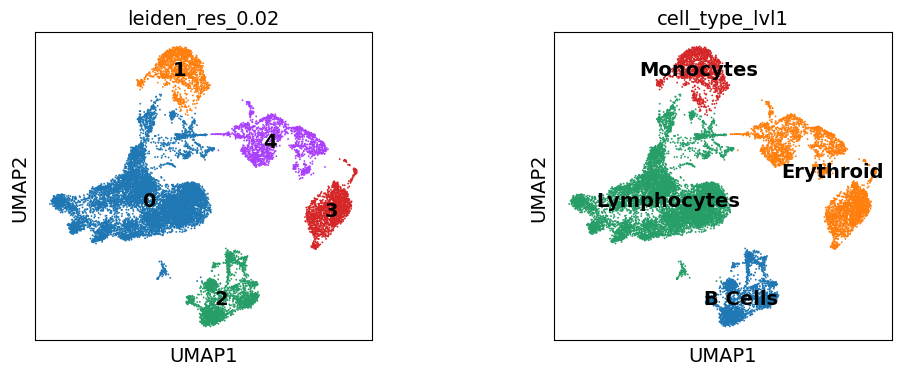

In [ ]:
sc.pl.umap(adata, color=["leiden_res_0.02", "cell_type_lvl1"], legend_loc="on data", wspace=0.4)

### Differentially-expressed Genes as Markers

In [ ]:
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(adata, groupby="leiden_res_0.50", method="wilcoxon")

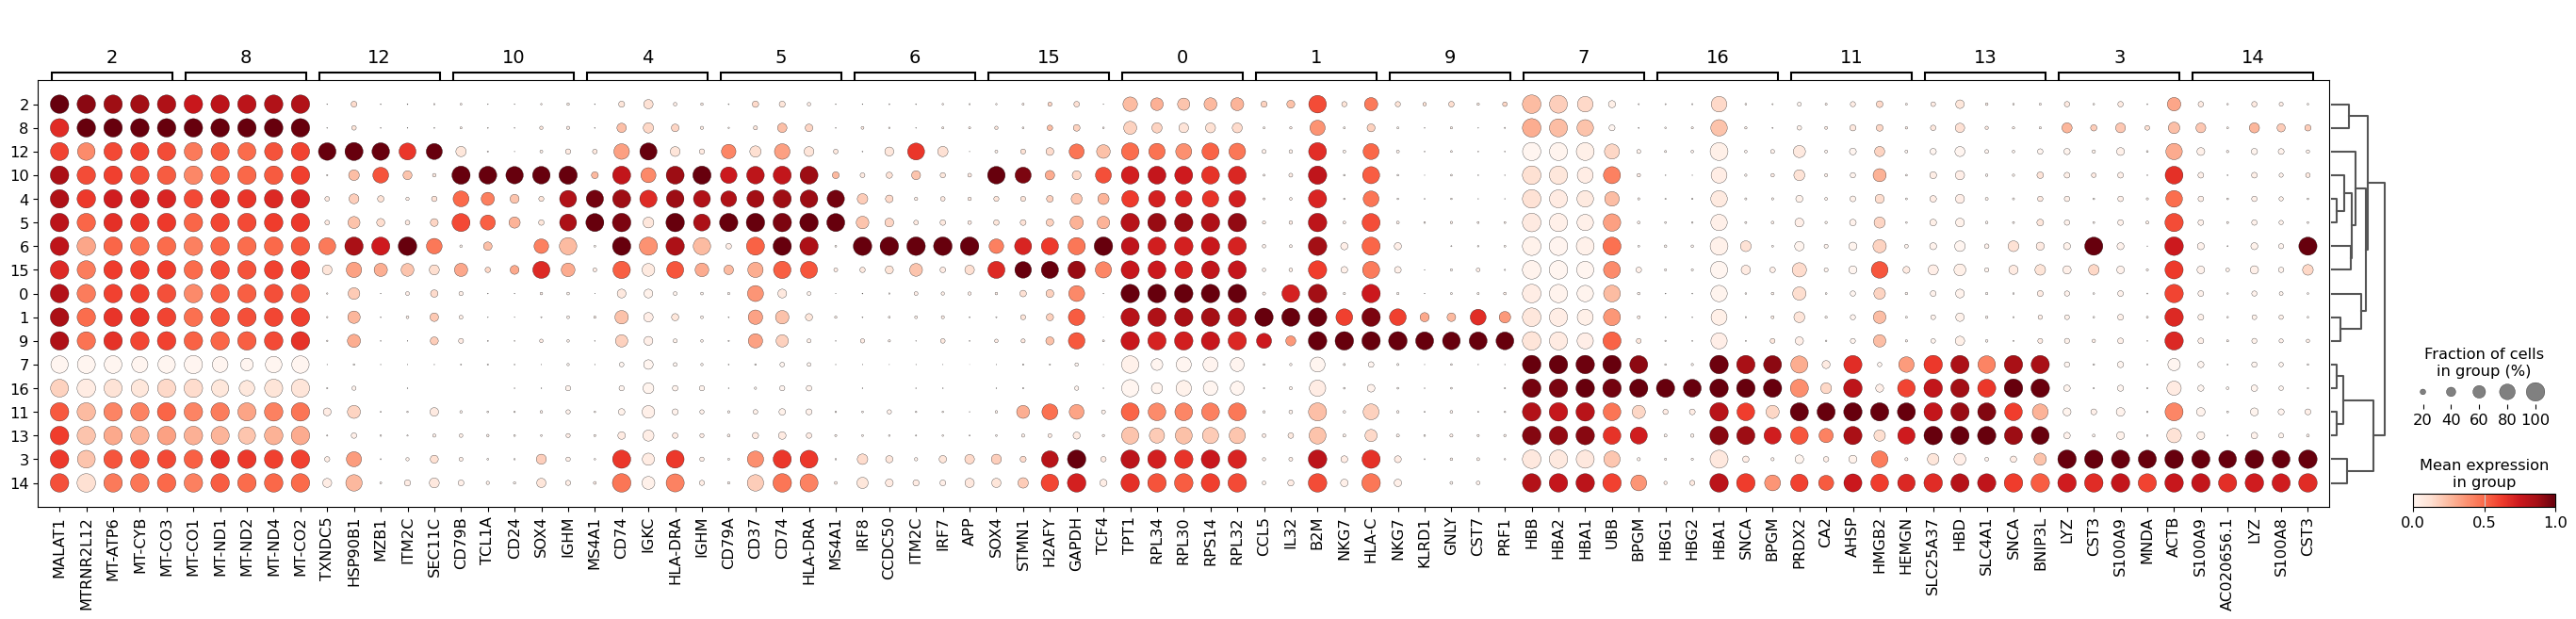

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden_res_0.50", standard_scale="var", n_genes=5
)

In [ ]:
sc.get.rank_genes_groups_df(adata, group="7").head(5)

,names,scores,logfoldchanges,pvals,pvals_adj
0,HBB,67.314583,6.943446,0.0,0.0
1,HBA2,66.814796,6.726576,0.0,0.0
2,HBA1,65.370865,6.620908,0.0,0.0
3,UBB,65.043327,3.474247,0.0,0.0
4,BPGM,61.799911,4.753799,0.0,0.0


---
## Part B: Classifying cells (Module 11)

### Cell 1: Import tools and define settings

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
LABEL_COLUMN = "cell_type_lvl1"
POSITIVE_LABEL = "B Cells"
N_GENES = 500
N_JOBS = 2

### Cell 2: Prepare expression data and split the cells

In [ ]:
if LABEL_COLUMN not in adata.obs:
    raise ValueError("Run the tutorial's cell-type annotation cell first.")

if "counts" not in adata.layers:
    raise ValueError("The tutorial's saved counts layer is missing.")

# Exclude cells with missing annotations.
keep = adata.obs[LABEL_COLUMN].notna().to_numpy()
labels = adata.obs.loc[keep, LABEL_COLUMN].astype(str)

if POSITIVE_LABEL not in labels.unique():
    raise ValueError(
        f"{POSITIVE_LABEL!r} was not found. "
        f"Available labels: {sorted(labels.unique())}"
    )

y = (labels == POSITIVE_LABEL).to_numpy(dtype=int)
cell_indices = np.flatnonzero(keep)

# Copy the saved counts into a separate sparse matrix.
X = sparse.csr_matrix(
    adata.layers["counts"][keep], dtype=np.float64
).copy()

if not np.isfinite(X.data).all() or (X.data < 0).any():
    raise ValueError("Expected finite, nonnegative counts.")

if np.any(np.asarray(X.sum(axis=1)).ravel() == 0):
    raise ValueError("Found cells with zero total counts.")

# Each cell is transformed independently using a fixed target.
X = normalize(X, norm="l1", axis=1) * 10_000
X.data = np.log1p(X.data)
X = X.tocsr()

# Reserve 20% for testing.
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

# Reserve 25% of the remaining 80% for validation.
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    stratify=y[trainval_idx],
    random_state=SEED,
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

if np.bincount(y_train, minlength=2).min() < 5:
    raise ValueError(
        "Five-fold CV requires at least five training cells per class."
    )

summary = pd.DataFrame([
    {
        "Partition": name,
        "Cells": len(target),
        "B Cells": int(target.sum()),
        "Other cells": int((target == 0).sum()),
        "B-cell fraction": target.mean(),
    }
    for name, target in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]
])

display(summary.round(3))
print("Positive class: B Cells (1)")
print("Negative class: other annotated cells (0)")
print("Expression matrix:", X.shape)

,Partition,Cells,B Cells,Other cells,B-cell fraction
0,Training,10224,1361,8863,0.133
1,Validation,3408,454,2954,0.133
2,Test,3409,454,2955,0.133


Positive class: B Cells (1)
Negative class: other annotated cells (0)
Expression matrix: (17041, 23427)


### Cell 3: Define pipelines and search grids

In [ ]:
def make_classifier_pipeline(classifier, scale=False):
    steps = [
        ("remove_constant", VarianceThreshold()),
        ("select_genes", SelectKBest(score_func=f_classif, k=N_GENES)),
    ]

    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))

    steps.append(("classifier", classifier))
    return Pipeline(steps)


model_specs = {
    "Logistic regression": (
        make_classifier_pipeline(
            LogisticRegression(
                solver="liblinear",
                max_iter=5000,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.01, 0.1, 1.0],
        },
    ),

    "Random forest": (
        make_classifier_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=SEED,
                n_jobs=1,
            )
        ),
        {
            "classifier__max_depth": [10, None],
            "classifier__min_samples_leaf": [1, 5],
        },
    ),

    "RBF SVM": (
        make_classifier_pipeline(
            SVC(
                kernel="rbf",
                probability=False,
                cache_size=300,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__gamma": ["scale", 0.001],
        },
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

### Cell 4: Run five-fold grid search and choose the classifier

In [ ]:
def positive_scores(model, features):
    """Return continuous scores for positive class 1."""
    if hasattr(model, "predict_proba"):
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        return model.predict_proba(features)[:, positive_column]

    if not np.array_equal(model.classes_, np.array([0, 1])):
        raise ValueError("Expected binary classes [0, 1].")

    return model.decision_function(features)


searches = {}
validation_scores = {}
comparison_rows = []

for name, (pipeline, grid) in model_specs.items():
    print(f"\nRunning five-fold grid search: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    # Only training data enter grid search.
    search.fit(X_train, y_train)
    searches[name] = search

    scores = positive_scores(search.best_estimator_, X_val)
    validation_scores[name] = scores

    comparison_rows.append({
        "Classifier": name,
        "CV average precision": search.best_score_,
        "CV AP SD": search.cv_results_["std_test_score"][search.best_index_],
        "Validation average precision": average_precision_score(y_val, scores),
        "Validation ROC-AUC": roc_auc_score(y_val, scores),
        "Best parameters": search.best_params_,
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Classifier")
    .sort_values(
        "Validation average precision",
        ascending=False,
        kind="stable",
    )
)

display(comparison.round(4))

winner_name = comparison.index[0]
winner_model = searches[winner_name].best_estimator_

print(f"\nSelected classifier: {winner_name}")
print("Selection criterion: highest validation average precision")
print("The test set has not been used for model selection.")


Running five-fold grid search: Logistic regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Running five-fold grid search: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running five-fold grid search: RBF SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,CV average precision,CV AP SD,Validation average precision,Validation ROC-AUC,Best parameters
Classifier,,,,,
RBF SVM,0.9988,0.0008,0.9986,0.9998,"{'classifier__C': 1.0, 'classifier__gamma': 0...."
Random forest,0.9985,0.0008,0.9977,0.9997,"{'classifier__max_depth': None, 'classifier__m..."
Logistic regression,0.9981,0.0013,0.9972,0.9996,{'classifier__C': 0.1}



Selected classifier: RBF SVM
Selection criterion: highest validation average precision
The test set has not been used for model selection.


### Cell 5: Compare validation ROC curves

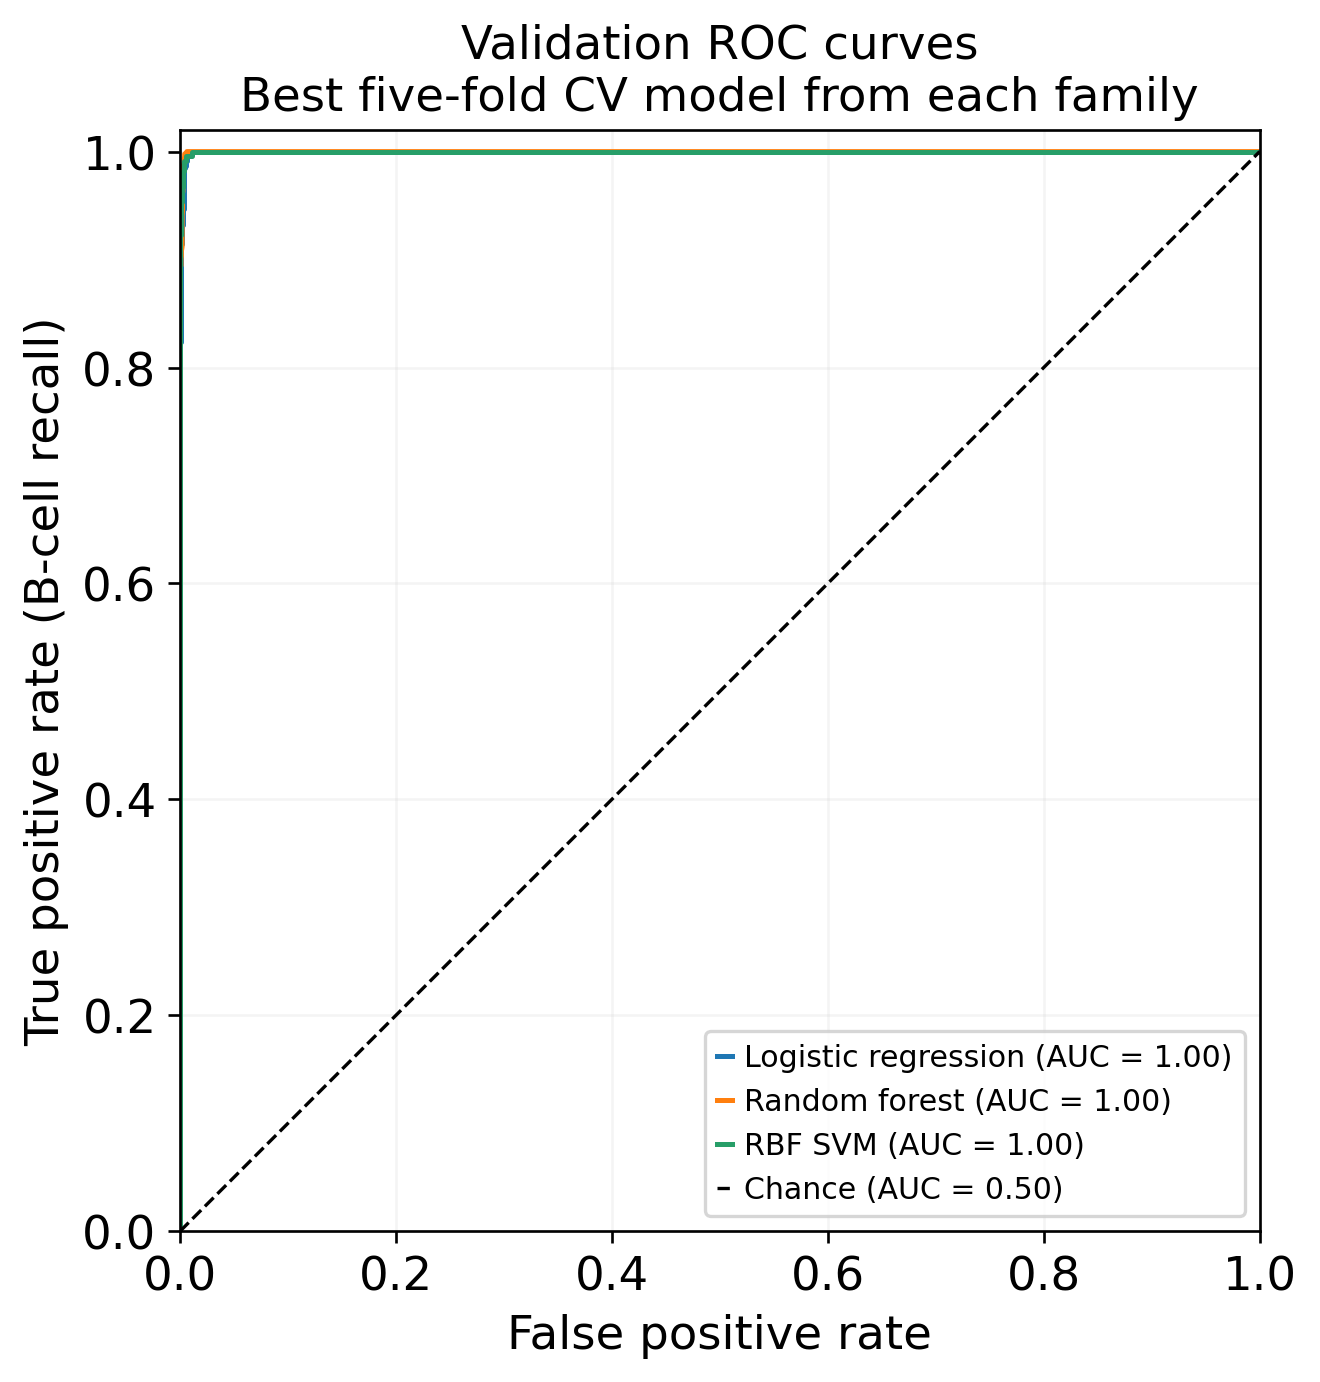

Winner by validation average precision: RBF SVM
ROC-AUC is displayed for comparison; it did not choose the winner.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=120)

for name, scores in validation_scores.items():
    RocCurveDisplay.from_predictions(
        y_val,
        scores,
        name=name,
        ax=ax,
    )

ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Chance (AUC = 0.50)",
)
ax.set(
    title="Validation ROC curves\nBest five-fold CV model from each family",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"Winner by validation average precision: {winner_name}\n"
    "ROC-AUC is displayed for comparison; it did not choose the winner."
)

### Cell 6: Evaluate the winner on the test set

Final test evaluation: RBF SVM
Test average precision: 0.9978
Test ROC-AUC:           0.9997
Test B-cell prevalence: 0.1332

Classification report at the model's default threshold:

                       precision    recall  f1-score   support

Other annotated cells      0.997     0.995     0.996      2955
              B Cells      0.967     0.982     0.975       454

             accuracy                          0.993      3409
            macro avg      0.982     0.989     0.985      3409
         weighted avg      0.993     0.993     0.993      3409



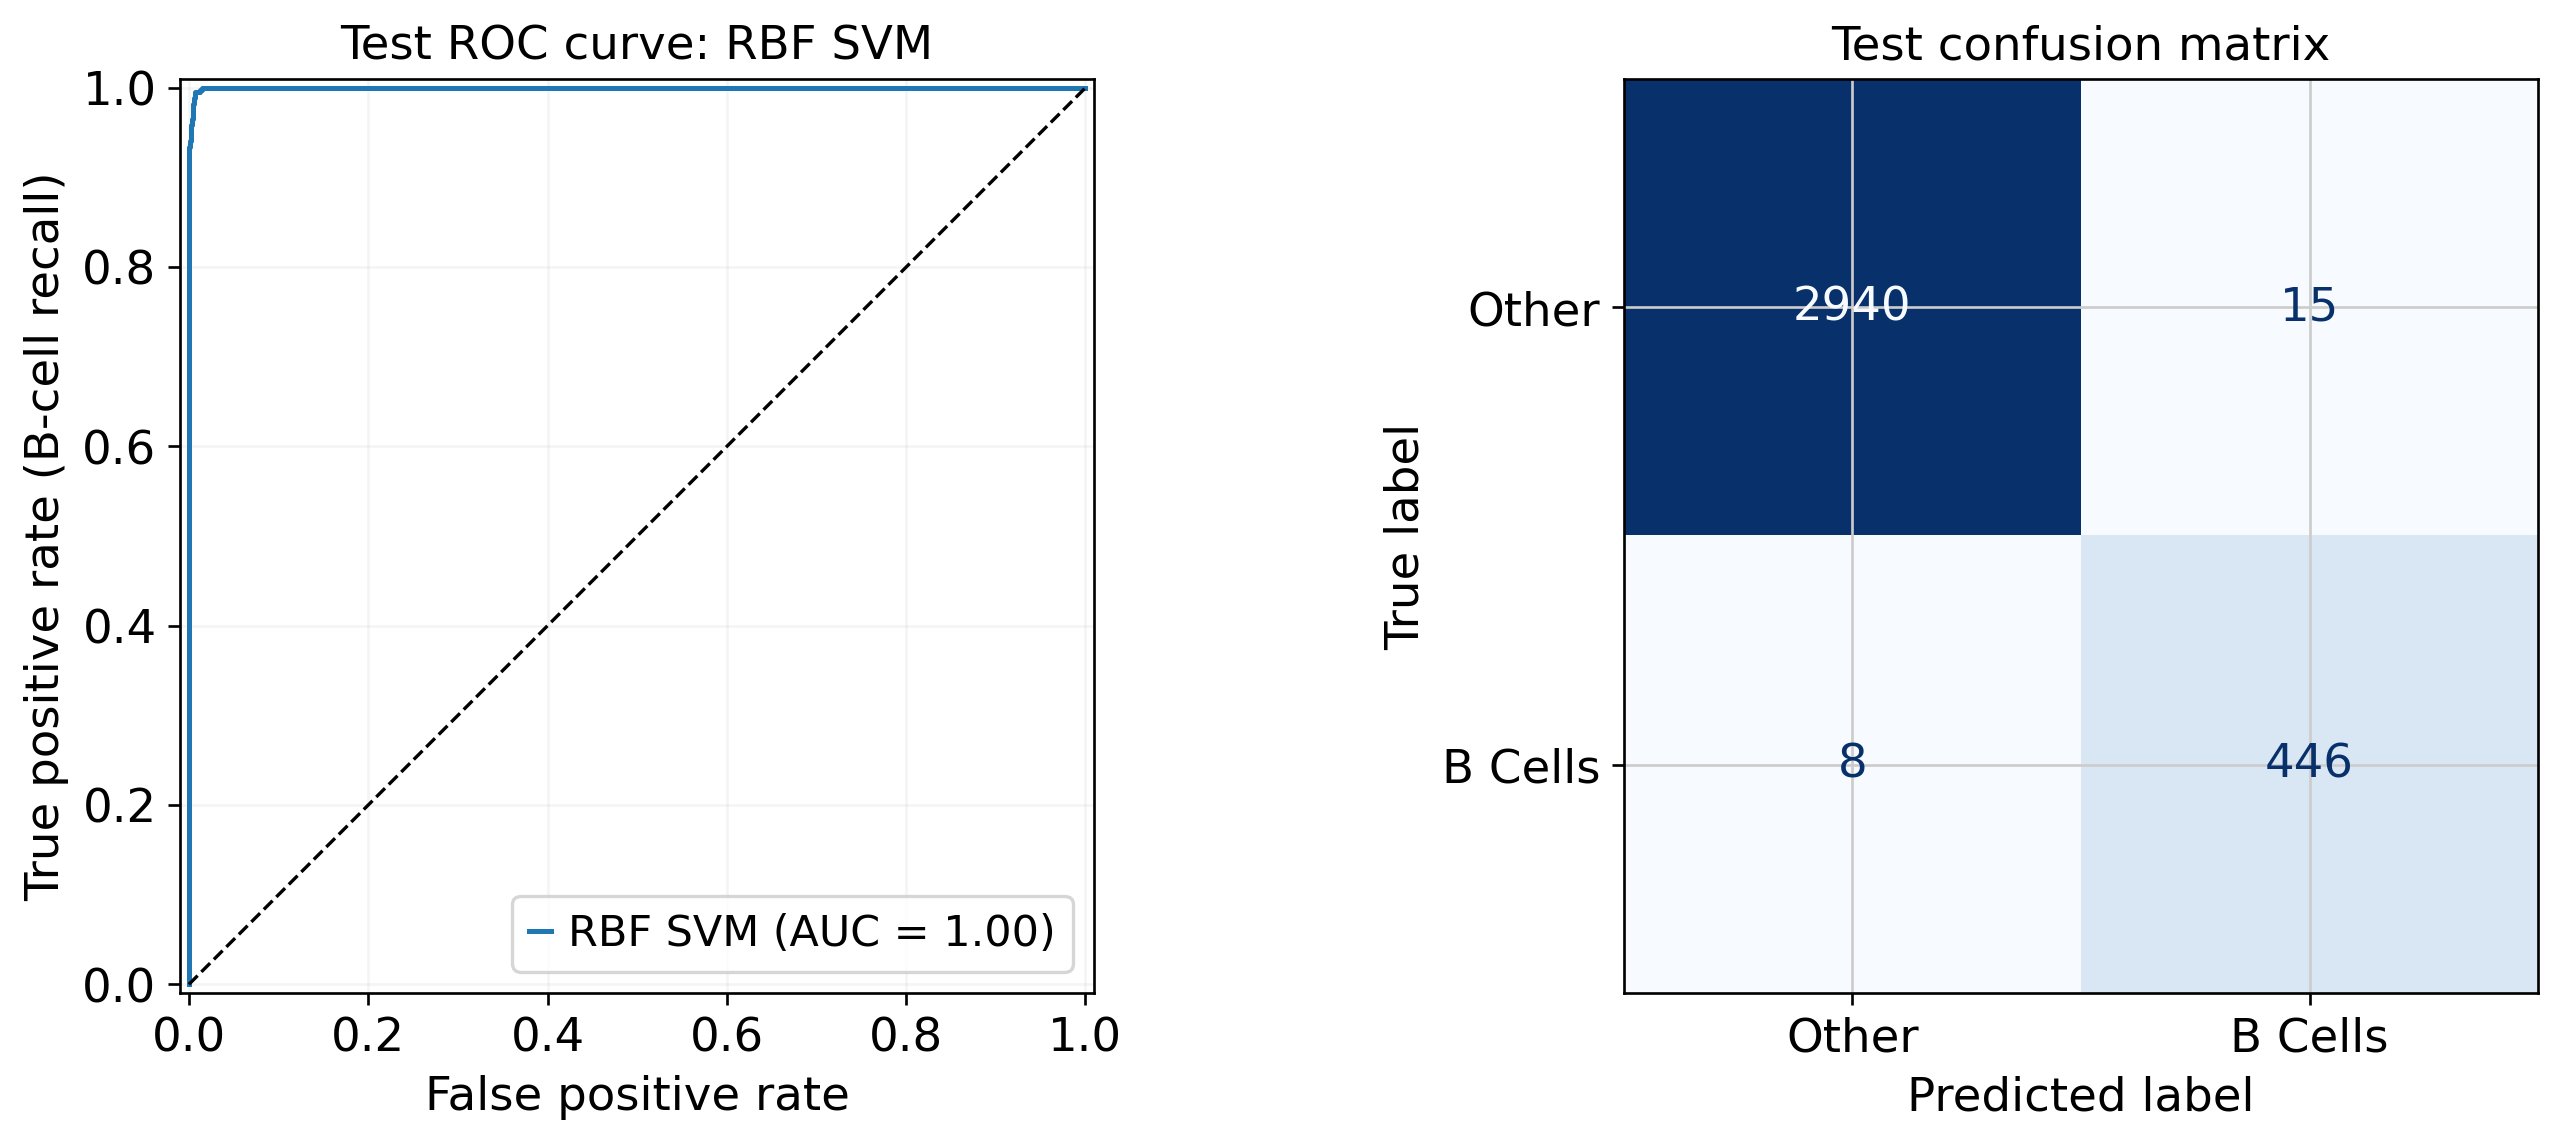

,cell_id,reference_label,predicted_label,positive_class_score,correct
0,ATTCCTAAGTCTGGTT-1,0,0,-3.123282,True
1,CCCGGAAGTCGAAACG-1,0,0,-1.761799,True
2,GTCCTCAGTGCAGGAT-1,0,0,-1.489165,True
3,GCTGAATGTCTTTCTA-1,0,0,-3.174368,True
4,GGGTCACTCGCATAGT-1,0,0,-1.702041,True


In [ ]:
test_scores = positive_scores(winner_model, X_test)
test_predictions = winner_model.predict(X_test)

test_ap = average_precision_score(y_test, test_scores)
test_auc = roc_auc_score(y_test, test_scores)

print(f"Final test evaluation: {winner_name}")
print(f"Test average precision: {test_ap:.4f}")
print(f"Test ROC-AUC:           {test_auc:.4f}")
print(f"Test B-cell prevalence: {y_test.mean():.4f}")
print("\nClassification report at the model's default threshold:\n")

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Other annotated cells", "B Cells"],
    digits=3,
    zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=winner_name,
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(
    title=f"Test ROC curve: {winner_name}",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
)
axes[0].grid(alpha=0.2)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "B Cells"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1],
)
axes[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()

test_results = pd.DataFrame({
    "cell_id": adata.obs_names[cell_indices[test_idx]].to_numpy(),
    "reference_label": y_test,
    "predicted_label": test_predictions,
    "positive_class_score": test_scores,
})
test_results["correct"] = (
    test_results["reference_label"] == test_results["predicted_label"]
)

display(test_results.head())

In [ ]:
print(searches["RBF SVM"].best_params_)

{'classifier__C': 1.0, 'classifier__gamma': 0.001}


## Exit questions

### 1. Define the classification problem
What are the observations, predictor features, and target labels in this classification problem?

The observations are individual cells (rows of the expression matrix). The predictor features are the log-normalized expression values of genes; within each training fold the pipeline keeps the 500 genes most associated with the label (ANOVA F-test) after dropping constant genes. The target label is binary: B Cells = 1 versus all other annotated cell types = 0, taken from the `cell_type_lvl1` annotation.

### 2. Establish a baseline
Using the training partition, calculate the accuracy of a classifier that predicts "Other" for every cell. What would its B-cell recall be? Why stratify the split?

In the training partition, 1,361 of 10,224 cells are B cells (13.3%), so 8,863 are 'Other'. A classifier that predicts 'Other' for every cell would be correct for 8,863 / 10,224 = 0.867. It never predicts a B cell, so TP = 0 and B-cell recall = 0 / (0 + 1,361) = 0.0. Accuracy alone is misleading here because a model that finds no B cells still scores about 87%. Stratifying keeps the B-cell fraction at 0.133 in training, validation and test, which matters because B cells are the rarer class. Without it, a partition could by chance contain too few B cells, making metrics noisy or leaving CV folds without enough positives.

### 3. Identify the selected model
Which classifier was selected, and what were its best hyperparameters?

The RBF SVM was selected because it had the highest validation average precision (0.9986), just ahead of random forest (0.9977) and logistic regression (0.9972). Its best hyperparameters were C = 1.0 and gamma = 0.001. The three families were nearly identical (validation ROC-AUC 0.9998, 0.9997 and 0.9996), so the choice of winner rests on very small differences that are probably within noise.

### 4. Interpret what the classifier learned
What did the classifier learn to predict? How does this differ from independently establishing a cell's biological identity?

The classifier learned to reproduce the tutorial's cluster-based B Cell annotation from expression patterns, i.e. which genes (such as B-cell markers like MS4A1 or CD79A, if these were selected) distinguish cells that were labeled B Cells from those that were not. It predicts the label, not the biology. Those labels were produced by clustering and marker-based annotation, so any errors or arbitrary boundaries in them are inherited. Independently establishing identity would need evidence outside this pipeline, such as protein markers (CITE-seq or flow cytometry), a curated reference atlas, or functional assays.

### 5. Interpret classification errors
What would a false positive and a false negative mean in this analysis?

A false positive is a cell annotated as another type that the classifier calls a B cell, for example a plasma cell or a cell with ambient/doublet B-cell RNA. A false negative is an annotated B cell that the classifier calls "Other", meaning a B cell is missed, which would undercount B cells in a sample. Both can also reflect noisy labels or cells near a cluster boundary rather than a true model failure.

### 6. Evaluate the classifier
Is the selected classifier a good classifier for this task? Justify your answer using its test-set sensitivity, precision, specificity, and F1 score. Calculate specificity from the confusion matrix as TN / (TN + FP).

From the test confusion matrix, TN = 2,940, FP = 15, FN = 8 and TP = 446. Sensitivity = 446 / 454 = 0.982. Precision = 446 / 461 = 0.967. Specificity = 2,940 / 2,955 = 0.995. F1 = 0.975. Test average precision was 0.9978 against a B-cell prevalence of 0.133, and ROC-AUC was 0.9997. The classifier is very good at this task. It misses only 8 of 454 B cells and wrongly flags only 15 of 2,955 other cells, far better than the always-'Other' baseline (accuracy 0.867, recall 0). However, this reflects how well it reproduces the cluster-derived labels, not that it identifies B cells in new data.

### 7. Assess independence and leakage
The classifier's gene selection, scaling, and hyperparameter tuning use only training data. However, the tutorial generated the cell-type labels by clustering and annotating the full dataset before the split.

Is the test set fully independent of the complete analysis? Explain how test cells influenced the upstream analysis, what this means for interpreting high test accuracy, and what a stronger evaluation would require.

No. The test cells were included in the tutorial's normalization, highly variable gene selection, PCA, neighbor graph and clustering, and the cluster annotations (the labels themselves) were defined using all cells, including those later held out. So test labels were shaped partly by test-cell expression, and the clusters are already organized around the same expression differences the classifier uses. High test accuracy is therefore optimistic: it shows the classifier can recover the clustering-derived labels, not that it would generalize to new data or to labels assigned independently. A stronger evaluation would split cells (ideally by donor/sample) before any upstream analysis, build the labels using only training cells, and then apply them to the held-out cells, or use an external test dataset or labels from an independent method such as protein markers or manual expert annotation.